In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import seaborn as sns
from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

from matplotlib.collections import LineCollection
from matplotlib import colors as mcolors
import scipy
import h5py

# Saving to the figure S5

In [3]:
prefix = '/mnt/staging/' # or 
mouse='cm229'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(FIGURES / "figure6") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"

h5_root = step_3_root+mouse+'/dlc_h5s/'
video_root = step_3_root+mouse+'/dlc_movies/'
raw_full_video_root = step_3_root+mouse+'/dc_full_front/'
mirror_h5_root = step_3_root+mouse+'/dlc_mirror_h5s/'
figure_config_root = str(PREPARES / "config") + "/"

fetch_path_integrated = str(PREPARES / "epochs-integrated") + "/"
fetch_path_CLS = str(PREPARES / "CLS") + "/"

In [4]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#ee8c7d'
palatte_dict['tail'] = 'palegreen'

import matplotlib.colors as mcolors
# palatte_dict.pop('tail')
# Convert hex colors to RGB
dict_rgb_colors = {}
for bdp in palatte_dict:
    dict_rgb_colors[bdp] = [mcolors.hex2color(palatte_dict[bdp])]

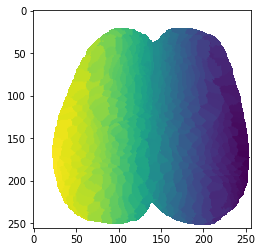

In [5]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    IDX_mask = IDX_sorted>-100
    IDX_mask = IDX_mask.astype('float')
    IDX_mask[IDX_mask==0]=np.nan
plt.imshow(IDX_sorted)

In [6]:
# load midline
with h5py.File(figure_config_root+'mask_midline_v2_'+mouse+'.mat','r') as f_midline:
    mask_midline = np.array(f_midline['mask_midline']).T
IDX_mask = np.multiply(IDX_mask,mask_midline)

In [7]:
mouse_id = mouse

M2_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse)
sensory_ind = load_pickle(fetch_path_S1+'brightest_ind_'+mouse)

extra_extra_ind = load_pickle(fetch_path_extra+'extra_extra_ind_'+mouse_id)
extra_ind = load_pickle(fetch_path_extra+'extra_ind_'+mouse_id)


# load integrated data

In [8]:
mouse_id='cm229'

In [9]:
pd_ind = pd.DataFrame()
pd_ind['day_label']=['cm229_5_runD','cm229_5_runD','cm229_4_runC','cm229_10_runD',
                     'cm229_11_runC','cm229_11_runM','cm229_11_runM','cm229_11_runM',
                     'cm229_11_runM','cm229_11_runM','cm229_11_runM','cm229_11_runM',
                     'cm229_11_runM','cm229_11_runM','cm229_11_runM','cm229_11_runL']
pd_ind['which_bout'] = [0,1,2,3,4,5,6,8,9,10,11,12,13,14,15,16]
pd_ind['ind']=[9756,10092,26688,29076,12152,5052,5584,10332,16584,17804,24900,26444,28348,29408,32580,19912]
pd_ind['move']=[35,0,20,46,35,0,37,30,39,45,45,54,47,56,35,37]
pd_ind['rise']=[42,55,26,57,58,51,54,46,53,59,60,60,55,58,55,56]
pd_ind['lick']=[44,61,33,59,60,57,59,58,63,74,64,70,63,60,59,61]

T_PRE=60

f = scipy.io.loadmat(fetch_path_integrated+mouse_id+'_FP_raw_exp5.mat')

all_gathered = ['M_day_label','M_LFP_vel','M_RFP_vel','M_ind','M_is_groom','M_rotf',
               'M_body_pc']
for key in all_gathered:
    exec("{} = f['{}']".format(key,key))
    if key not in ['M_ind','M_day_label']:
        exec("{} = {}[:,pd_ind['which_bout'].values]".format(key,key))
# cm229 - M_rotf BROKEN - re-extract in the full data step
pd_bar_graph = pd.DataFrame()
for i_bout in range(len(pd_ind)): 
    
    ind_move = pd_ind.loc[i_bout,'move']
    ind_rise = pd_ind.loc[i_bout,'rise']  
    ind_lick = pd_ind.loc[i_bout,'lick']  
    # if ind_move ==0:
    #     pd_bar_graph.loc[i_bout,'rest']=0
    # else:
    #     pd_bar_graph.loc[i_bout,'rest']=5
    pd_bar_graph.loc[i_bout,'move']=ind_rise-ind_move
    pd_bar_graph.loc[i_bout,'rise'] = ind_lick-ind_rise
    pd_bar_graph.loc[i_bout,'lick'] = 15

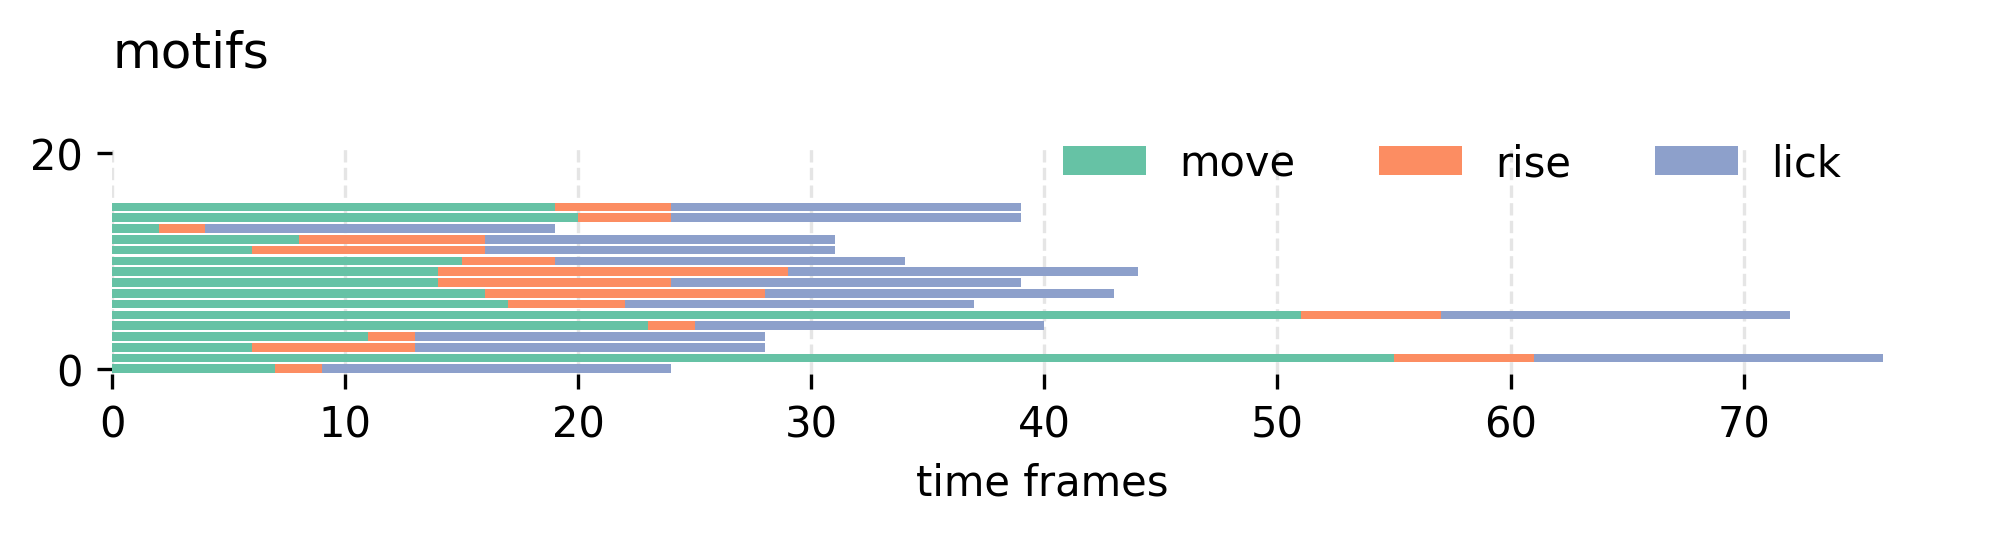

In [10]:
fields = ['move','rise','lick']
colors = ['#1D2F6F', '#8390FA', '#6EAF46', '#FAC748']
colors = ['#FAEE02','#015EB5','#df2f2b','#ABC9E3','#3a5697']
colors = sns.color_palette("Set2")
labels = ['move','rise','lick']
# figure and axis
fig, ax = plt.subplots(1, figsize=(8, 1),dpi=300)
# plot bars
left = len(pd_bar_graph) * [0]
for idx, name in enumerate(fields):
    plt.barh(pd_bar_graph.index, pd_bar_graph[name], left = left, color=colors[idx])
    left = left + pd_bar_graph[name]

    # title, legend, labels
plt.title('motifs\n', loc='left')
plt.legend(labels, bbox_to_anchor=([0.25, 1, 0.7, 0.19]), ncol=4, frameon=False)
plt.xlabel('time frames')

    
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
# adjust limits and draw grid lines
plt.ylim(-0.5, ax.get_yticks()[-1] + 0.5)
ax.set_axisbelow(True)
ax.xaxis.grid(color='gray', linestyle='dashed',alpha=0.2)

In [11]:
T_POST = 60;mouse='cm229'

In [12]:
len_move_2_rise = int(np.mean(pd_ind['rise']-pd_ind['move']))
len_rise_2_lick = int(np.mean(pd_ind['lick']-pd_ind['rise']))
len_lick =  100
timestamp_m_2_r = np.linspace(0,len_move_2_rise-1,len_move_2_rise)
timestamp_r_2_l = np.linspace(0,len_rise_2_lick-1,len_rise_2_lick)
# timestamp_l = np.linspace(0,len_lick-1,len_lick)

total_num_frames = len_move_2_rise+len_rise_2_lick+len_lick

MM_jrgeco=np.empty((256,256,total_num_frames,0))
MM_gcamp=np.empty((256,256,total_num_frames,0))

print('len_move_2_rise',len_move_2_rise,'len_rise_2_lick',len_rise_2_lick,'len_lick',len_lick)

selected_behavior_list = ['M_RFP_vel','M_LFP_vel','M_is_groom','M_rotf']
behavior_short_dict = {key:[] for key in selected_behavior_list}
behaviors = {key:np.empty((total_num_frames,0)) for key in behavior_short_dict}


from scipy import interpolate
for i_bout in range(len(pd_ind)): 
    session_id = pd_ind.loc[i_bout,'day_label']
    day = session_id.split(mouse+'_')[1].split('_')[0]
    run_id = session_id.split(mouse+'_')[1].split('_')[1]

    f3 = list(set(glob.glob(step_1_root+mouse+"/"+day+"/*"+run_id+"*.mat")))[0]
    
    #cut 
    ind_move = pd_ind.loc[i_bout,'move']
    ind_rise = pd_ind.loc[i_bout,'rise']  
    ind_lick_start = pd_ind.loc[i_bout,'lick']  
    ind_lick_end = pd_ind.loc[i_bout,'lick']+200
    
    ind = int(pd_ind.loc[i_bout,'ind']/4)
    
    temp_jrgeco_here=np.empty((256,256,0))
    temp_gcamp_here=np.empty((256,256,0))    
    
    big_temp_jrgeco=np.ones((256,256,total_num_frames));big_temp_jrgeco[:]=np.nan
    big_temp_gcamp=np.ones((256,256,total_num_frames));big_temp_gcamp[:]=np.nan 
    for i_bev, behavior in enumerate(selected_behavior_list):
        exec("temp_{} = np.empty(0)".format(behavior))
        exec("big_temp_{} = np.ones(total_num_frames);big_temp_{}[:]=np.nan".format(behavior,behavior))
        
    with h5py.File(f3,'r') as f_H: 
        m = f_H['m']
        C = np.array(f_H['C']['jrgeco'])
        S = np.array(f_H['S']['jrgeco'])[ind-T_PRE:ind+T_POST,:]
        # cut [-60,60] frames slice
        mask = np.array(f_H['mask'])
        # nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
        nanidx = np.squeeze(m['nanidx'])==1
        CS = np.dot(S,C).transpose()
        jrgeco = np.zeros((len(nanidx),CS.shape[-1]))
        jrgeco[:] = np.nan
        jrgeco[nanidx==True,:] = CS
        jrgeco = jrgeco.reshape((256,256,-1)).transpose((1,0,2))

        C = np.array(f_H['C']['gcamp'])
        S = np.array(f_H['S']['gcamp'])[ind-T_PRE:ind+T_POST,:]
        # cut [-60,60] frames slice
        CS = np.dot(S,C).transpose()
        gcamp = np.zeros((len(nanidx),CS.shape[-1]))
        gcamp[:] = np.nan
        gcamp[nanidx==True,:] = CS
        gcamp = gcamp.reshape((256,256,-1)).transpose((1,0,2))        
        
        
        a=np.array(m['DAQ_ds'])
        rot = np.rad2deg(np.unwrap(a[:,-1]))
        rot = np.diff(rot)
        z = np.abs(stats.zscore(rot))
        threshold = 3
        outlier_ind = np.squeeze(np.where(z > 5))
        rot[outlier_ind]=np.nan
        rot[0]=0
        rot_smooth_full_single_trial = np.array(stats.zscore(np.squeeze(pd.DataFrame(rot).interpolate().rolling(20).mean().fillna(0))))
        # rot_smooth_full_single_trial = rot_smooth_full_single_trial)
        M_rotf = np.repeat(stats.zscore(rot_smooth_full_single_trial[ind-T_PRE:ind+T_POST])[:,np.newaxis],repeats=len(pd_ind),axis=1)

        
#         # de-baseline too
#         jrgeco_m_2_r = jrgeco[:,:,ind_move:ind_rise]-np.mean(jrgeco[:,:,ind_move:ind_rise],axis=-1)[:,:,np.newaxis]
#         gcamp_m_2_r = gcamp[:,:,ind_move:ind_rise]-np.mean(gcamp[:,:,ind_move:ind_rise],axis=-1)[:,:,np.newaxis]
#         jrgeco_r_2_l = jrgeco[:,:,ind_rise:ind_lick_start]-np.mean(jrgeco[:,:,ind_move:ind_rise],axis=-1)[:,:,np.newaxis]
#         gcamp_r_2_l = gcamp[:,:,ind_rise:ind_lick_start] -np.mean(gcamp[:,:,ind_move:ind_rise],axis=-1)[:,:,np.newaxis]
#         jrgeco_l = jrgeco[:,:,ind_lick_start:ind_lick_end]-np.mean(jrgeco[:,:,ind_move:ind_rise],axis=-1)[:,:,np.newaxis]
#         gcamp_l = gcamp[:,:,ind_lick_start:ind_lick_end] -np.mean(gcamp[:,:,ind_move:ind_rise],axis=-1)[:,:,np.newaxis]
        
        # DO NOT de-baseline HERE
        jrgeco_m_2_r = jrgeco[:,:,ind_move:ind_rise]#-np.mean(jrgeco[:,:,ind_move:ind_rise],axis=-1)[:,:,np.newaxis]
        gcamp_m_2_r = gcamp[:,:,ind_move:ind_rise]#-np.mean(gcamp[:,:,ind_move:ind_rise],axis=-1)[:,:,np.newaxis]
        jrgeco_r_2_l = jrgeco[:,:,ind_rise:ind_lick_start]#-np.mean(jrgeco[:,:,ind_move:ind_rise],axis=-1)[:,:,np.newaxis]
        gcamp_r_2_l = gcamp[:,:,ind_rise:ind_lick_start] #-np.mean(gcamp[:,:,ind_move:ind_rise],axis=-1)[:,:,np.newaxis]
        jrgeco_l = jrgeco[:,:,ind_lick_start:ind_lick_end]#-np.mean(jrgeco[:,:,ind_move:ind_rise],axis=-1)[:,:,np.newaxis]
        gcamp_l = gcamp[:,:,ind_lick_start:ind_lick_end] #-np.mean(gcamp[:,:,ind_move:ind_rise],axis=-1)[:,:,np.newaxis]
        
        
        timestamp_brain_m_2_r = np.linspace(0,len_move_2_rise-1,ind_rise-ind_move)
        timestamp_brain_r_2_l = np.linspace(0,len_rise_2_lick-1,ind_lick_start-ind_rise)
        # timestamp_brain_l = np.linspace(0,len_lick-1,ind_lick_end-ind_lick_start)
        # real interpolation
        for i_trunk,trunk in enumerate(['m_2_r','r_2_l']):
            for i_fluorofore,fluorophore in enumerate(['jrgeco','gcamp']):
                exec("func = interpolate.interp1d(timestamp_brain_{},{}_{},axis=-1)".format(trunk,fluorophore,trunk))
                exec("{}_{}_interp = func(timestamp_{})".format(fluorophore,trunk,trunk))
                exec("temp_{}_here = np.append(temp_{}_here,{}_{}_interp,axis=2)".format(fluorophore,fluorophore,fluorophore,trunk))
                # print(temp_jrgeco.shape)

        temp_jrgeco_here = np.append(temp_jrgeco_here,jrgeco_l,axis=2)
        temp_gcamp_here = np.append(temp_gcamp_here,gcamp_l,axis=2)
        big_temp_jrgeco[:,:,:temp_jrgeco_here.shape[-1]]=temp_jrgeco_here
        big_temp_gcamp[:,:,:temp_gcamp_here.shape[-1]]=temp_gcamp_here   
        MM_jrgeco = np.append(MM_jrgeco,big_temp_jrgeco[:,:,:,np.newaxis],axis=3)
        MM_gcamp = np.append(MM_gcamp,big_temp_gcamp[:,:,:,np.newaxis],axis=3)
        
        # print(M_gcamp.shape)
        
        
    ########################## BEHAVIOR ###########################
    for i_bev, behavior in enumerate(selected_behavior_list):
        # actual_bout = pd_ind.loc[i_bout,'which_bout']
        exec("{}_m_2_r = {}[ind_move:ind_rise,i_bout] - np.mean({}[ind_move:ind_rise,i_bout],axis=0)".format(behavior,behavior,behavior))
        exec("{}_r_2_l = {}[ind_rise:ind_lick_start,i_bout] - np.mean({}[ind_move:ind_rise,i_bout],axis=0)".format(behavior,behavior,behavior))
        exec("{}_l = {}[ind_lick_start:ind_lick_end,i_bout] - np.mean({}[ind_move:ind_rise,i_bout],axis=0)".format(behavior,behavior,behavior))

        # # un-normalized version
        # exec("{}_m_2_r = {}[ind_move:ind_rise,i_bout]".format(behavior,behavior))
        # exec("{}_r_2_l = {}[ind_rise:ind_lick_start,i_bout] ".format(behavior,behavior))
        # exec("{}_l = {}[ind_lick_start:ind_lick_end,i_bout] ".format(behavior,behavior))
        # normalized version
        # exec("{}_m_2_r = {}[ind_move:ind_rise,i_bout] - np.mean({}[ind_move:ind_rise,i_bout],axis=0)".format(behavior,behavior,behavior))
        # exec("{}_r_2_l = {}[ind_rise:ind_lick_start,i_bout] - np.mean({}[ind_move:ind_rise,i_bout],axis=0)".format(behavior[5:],behavior[5:],behavior[5:]))
        # exec("{}_l = {}[ind_lick_start:ind_lick_end,i_bout] - np.mean({}[ind_move:ind_rise,i_bout],axis=0)".format(behavior[5:],behavior[5:],behavior[5:]))

        for i_trunk,trunk in enumerate(['m_2_r','r_2_l']):
            exec("func = interpolate.interp1d(timestamp_brain_{},{}_{},axis=-1)".format(trunk,behavior,trunk))
            exec("{}_{}_interp = func(timestamp_{})".format(behavior,trunk,trunk))
            exec("temp_{} = np.append(temp_{},{}_{}_interp,axis=-1)".format(behavior,behavior,behavior,trunk))
        exec("temp_{} = np.append(temp_{},{}_l,axis=-1)".format(behavior,behavior,behavior))
        exec("big_temp_{}[:temp_{}.shape[-1]] = temp_{}".format(behavior,behavior,behavior))
        exec("behaviors[behavior]= np.append(behaviors[behavior],big_temp_{}[:,np.newaxis],axis=1)".format(behavior))
    # print(behaviors[behavior].shape)
                
print('done')    


len_move_2_rise 17 len_rise_2_lick 6 len_lick 100
done


In [13]:
list_select_behavior_2show = ['M_is_groom','M_LFP_vel','M_RFP_vel', 'M_rotf']

In [14]:
with h5py.File(figure_config_root+'mask_midline_v2_'+mouse+'.mat','r') as f_midline:
    mask_midline = np.array(f_midline['mask_midline']).T
ss_here = MM_jrgeco.shape
mask_midline_array = np.repeat(np.repeat(mask_midline[:,:,np.newaxis],
                     repeats=ss_here[2],axis=2)[:,:,:,np.newaxis],repeats=ss_here[3],axis=3)
MM_jrgeco = np.multiply(MM_jrgeco,mask_midline_array)
MM_gcamp = np.multiply(MM_gcamp,mask_midline_array)


In [15]:
len_move_2_rise

17

In [41]:
run_bsl = range(0,len_move_2_rise+3)
jrgeco_run = np.mean(MM_jrgeco[:,:,run_bsl,:],2)
gcamp_run = np.mean(MM_gcamp[:,:,run_bsl,:],2)
brain_map_gcamp_run = np.mean(gcamp_run,-1)
brain_map_jrgeco_run = np.mean(jrgeco_run,-1)

jrgeco_rise = np.mean(MM_jrgeco[:,:,len_move_2_rise+5:len_move_2_rise+len_rise_2_lick,:],2)
jrgeco_lick = np.mean(MM_jrgeco[:,:,len_move_2_rise+len_rise_2_lick+2:len_move_2_rise+len_rise_2_lick+10,:],2)
brain_map_jrgeco_rise = np.mean(jrgeco_rise - jrgeco_run,-1)
brain_map_jrgeco_lick = np.mean(jrgeco_lick - jrgeco_run,-1)

gcamp_rise = np.mean(MM_gcamp[:,:,len_move_2_rise+5:len_move_2_rise+len_rise_2_lick,:],2)
gcamp_lick = np.mean(MM_gcamp[:,:,len_move_2_rise+len_rise_2_lick+2:len_move_2_rise+len_rise_2_lick+10,:],2)
brain_map_gcamp_rise = np.mean(gcamp_rise - gcamp_run,-1)
brain_map_gcamp_lick = np.mean(gcamp_lick - gcamp_run,-1)


jrgeco_rise_to_lick = np.mean(MM_jrgeco[:,:,len_move_2_rise+5:len_move_2_rise+len_rise_2_lick+10,:],2)
gcamp_rise_to_lick = np.mean(MM_gcamp[:,:,len_move_2_rise+5:len_move_2_rise+len_rise_2_lick+10:],2)


In [37]:
save_root = str(FIGURES / "figureS5") + "/"
dict_figure_S5_save = load_pickle(save_root+'csn_thy1_integrated_compare_save')
dict_figure_S5_save['jrgeco_rise_to_lick']=jrgeco_rise_to_lick
dict_figure_S5_save['gcamp_rise_to_lick']=gcamp_rise_to_lick
save_root = str(FIGURES / "figureS5") + "/"
save_pickle(dict_figure_S5_save,save_root+'csn_thy1_integrated_compare_save')

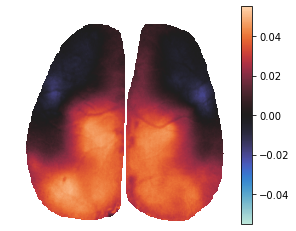

In [16]:
plt.imshow(brain_map_jrgeco_run,vmin=-0.055,vmax=0.055,cmap='icefire')
plt.axis('off')
plt.colorbar()

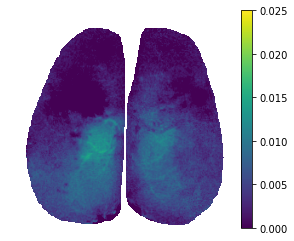

In [17]:
plt.imshow(brain_map_gcamp_run,vmin=-0.0,vmax=0.025,cmap='viridis')
plt.axis('off')
plt.colorbar()

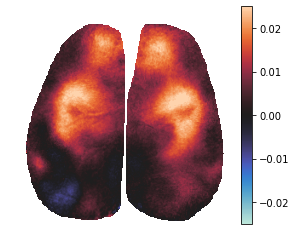

In [18]:
plt.imshow(brain_map_jrgeco_rise,vmin=-0.025,vmax=0.025,cmap='icefire')
plt.axis('off')
plt.colorbar()

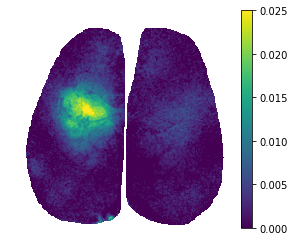

In [19]:
plt.imshow(brain_map_gcamp_rise,vmin=-0.0,vmax=0.025,cmap='viridis')
plt.axis('off')
plt.colorbar()


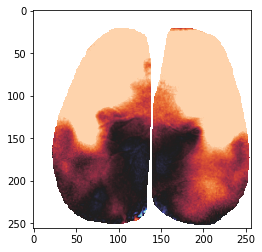

In [20]:
plt.imshow(brain_map_jrgeco_lick,vmin=-0.03,vmax=0.03,cmap='icefire')

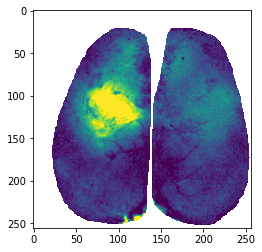

In [21]:
plt.imshow(brain_map_gcamp_lick,vmin=-0.0,vmax=0.03,cmap='viridis')

In [ ]:
new_choice_ind={}
new_choice_ind['M2']=M2_ind['RFP']
new_choice_ind['S1']=412 # for CM229
new_choice_ind['M1']=322 # for CM229

# get webcam images

In [22]:
webcam_root='/home/wx2203/hillman_servers/temp/hillman_servers/chronos/2/cmdata/'
day_label = 'cm229_11_runM'
day_name = day_label.split('_run')[0]
run_name = day_label.split(day_name)[1][1:]

# img_fname_after = webcam_root+'{}/webcam/{}/*{}*cam0*'.format(day_name,run_name,int(ind)+4)

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:9: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  if __name__ == '__main__':


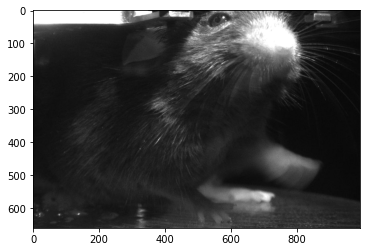

In [23]:
import imageio
dict_webcam_img = {}
ind_run = 5550

img_fname_before = webcam_root+'{}/webcam/{}/*_{}_*cam0*'.format(
    day_name,run_name,int(ind_run))

f1 = [f for f in glob.glob(img_fname_before, recursive=True)][0]
image_before = imageio.imread(f1)
plt.imshow(image_before[260:920,300:1292],cmap='gray')
dict_webcam_img['integrated_run']= image_before[260:920,300:1292]

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:6: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  


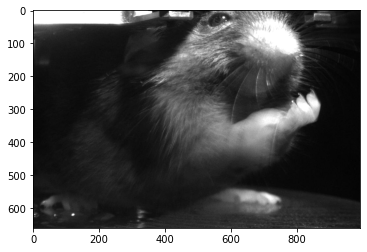

In [24]:
ind_rise = 5586
img_fname_before = webcam_root+'{}/webcam/{}/*_{}_*cam0*'.format(
    day_name,run_name,int(ind_rise))

f1 = [f for f in glob.glob(img_fname_before, recursive=True)][0]
image_before = imageio.imread(f1)
plt.imshow(image_before[260:920,300:1292],cmap='gray')
dict_webcam_img['integrated_rise']= image_before[260:920,300:1292]

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:7: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  import sys


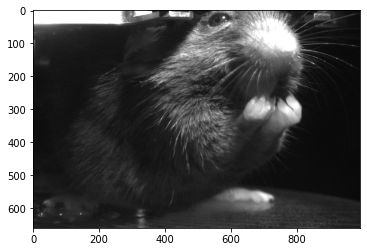

In [25]:
ind_lick = 5596

img_fname_before = webcam_root+'{}/webcam/{}/*_{}_*cam0*'.format(
    day_name,run_name,int(ind_lick))

f1 = [f for f in glob.glob(img_fname_before, recursive=True)][0]
image_before = imageio.imread(f1)
plt.imshow(image_before[260:920,300:1292],cmap='gray')
dict_webcam_img['integrated_lick']= image_before[260:920,300:1292]

In [27]:
dict_figure_S5_save = {
                       'MM_jrgeco':MM_jrgeco,
                       'MM_gcamp':MM_gcamp,
                       'jrgeco_run':jrgeco_run,
                       'jrgeco_rise':jrgeco_rise,
    'jrgeco_rise_to_lick':jrgeco_rise_to_lick,
    'gcamp_rise_to_lick':gcamp_rise_to_lick,
                       'jrgeco_lick':jrgeco_lick,
                       'gcamp_rise':gcamp_rise,
                       'gcamp_lick':gcamp_lick,
                       'gcamp_run':gcamp_run,
                      'brain_map_jrgeco_rise':brain_map_jrgeco_rise,
                      'brain_map_jrgeco_lick':brain_map_jrgeco_lick,
                      'brain_map_gcamp_rise':brain_map_gcamp_rise,
                      'brain_map_gcamp_lick':brain_map_gcamp_lick,
                       'brain_map_gcamp_run':brain_map_gcamp_run,
                       'brain_map_jrgeco_run':brain_map_jrgeco_run,
                       'dict_webcam_img':dict_webcam_img,
    'len_move_2_rise':len_move_2_rise,
    'len_rise_2_lick':len_rise_2_lick,
    
                      }

In [23]:
save_root = str(FIGURES / "figureS5") + "/"
save_pickle(dict_figure_S5_save,save_root+'csn_thy1_integrated_compare_save')